In [1]:
import os
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import Sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

sns.set_theme(style="whitegrid")
print("Pustaka komparasi 3 metode PBL Cafind dan Sastrawi berhasil dimuat.")

Pustaka komparasi 3 metode PBL Cafind dan Sastrawi berhasil dimuat.


In [2]:
# Memuat data ulasan dan aspek
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews):
    path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

# Menyiapkan stemmer Sastrawi
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Inisialisasi daftar stopword bahasa Indonesia standar
stopword_id = set([
    'yang', 'untuk', 'pada', 'ke', 'para', 'namun', 'menurut', 'antara', 'dia', 'dua',
    'ia', 'seperti', 'jika', 'sehingga', 'kembali', 'dan', 'ini', 'karena', 'oleh',
    'saat', 'dari', 'telah', 'bagi', 'akan', 'atau', 'serta', 'di', 'ada', 'itu',
    'bisa', 'saya', 'kami', 'kita', 'mereka', 'sudah', 'juga', 'lebih', 'banget', 'sih'
])

def pra_proses_indonesia(teks):
    if not isinstance(teks, str): return ""
    teks = teks.lower()
    teks = re.sub(r'[^a-zA-Z\s]', ' ', teks)
    tokens = [w for w in teks.split() if w not in stopword_id and len(w) > 2]
    return ' '.join(tokens)

# Gabung ulasan dan aspek sentimen
df_pbl = pd.merge(df_aspects[['review_id', 'sentiment']], df_reviews[['id', 'text']], left_on='review_id', right_on='id')
df_pbl = df_pbl.drop_duplicates(subset=['id', 'sentiment']).reset_index(drop=True)

df_pbl['clean_id'] = df_pbl['text'].apply(pra_proses_indonesia)
df_pbl = df_pbl[df_pbl['clean_id'].str.len() > 3].reset_index(drop=True)

print(f"Total dataset siap uji komparasi: {len(df_pbl):,} sampel")
print("Sampel Teks Hasil Pra-Pengolahan Bahasa Indonesia:")
for i in range(2):
    print(f"Asli   : {df_pbl['text'].iloc[i][:100]}...")
    print(f"Bersih : {df_pbl['clean_id'].iloc[i]}")
    print("-" * 50)

Total dataset siap uji komparasi: 6,620 sampel
Sampel Teks Hasil Pra-Pengolahan Bahasa Indonesia:
Asli   : Montblanc nya enak.. server nya cantik...
Bersih : montblanc nya enak server nya cantik
--------------------------------------------------
Asli   : Tempatnya nyaman, pelayanannya cepatt...
Bersih : tempatnya nyaman pelayanannya cepatt
--------------------------------------------------


In [3]:
# Pembagian data 80% train dan 20% test dengan stratifikasi
X = df_pbl['clean_id']
y = df_pbl['sentiment']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Vektorisasi TF-IDF dengan n-gram (1,2)
vectorizer = TfidfVectorizer(max_features=1200, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_raw)
X_test  = vectorizer.transform(X_test_raw)

print(f"Dimensi Fitur Pelatihan : {X_train.shape}")
print(f"Dimensi Fitur Pengujian : {X_test.shape}")
print("\nDistribusi Kelas Target (%):")
print((y.value_counts(normalize=True)*100).round(2).to_dict())

Dimensi Fitur Pelatihan : (5296, 1200)
Dimensi Fitur Pengujian : (1324, 1200)

Distribusi Kelas Target (%):
{'positive': 61.47, 'neutral': 33.72, 'negative': 4.82}


In [4]:
# Inisialisasi ketiga model utama PBL
model_knn = KNeighborsClassifier(n_neighbors=5, metric='cosine')
model_mnb = MultinomialNB(alpha=0.8)
model_svm = SVC(kernel='linear', C=1.5, class_weight='balanced', random_state=42)

model_dict = {
    'K-Nearest Neighbors (KNN)': model_knn,
    'Naive Bayes (MultinomialNB)': model_mnb,
    'Support Vector Machine (Linear SVM)': model_svm
}

hasil_komparasi = []

for nama, model in model_dict.items():
    # Pengukuran waktu latih
    t0 = time.time()
    model.fit(X_train, y_train)
    t_train = time.time() - t0
    
    # Pengukuran waktu inferensi
    t0 = time.time()
    y_pred = model.predict(X_test)
    t_infer = (time.time() - t0) / len(X_test_raw)
    
    # Perhitungan metrik
    acc = accuracy_score(y_test, y_pred)
    prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec_macro  = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1_macro   = f1_score(y_test, y_pred, average='macro', zero_division=0)
    f1_weight  = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    hasil_komparasi.append({
        'Model PBL': nama,
        'Akurasi (%)': round(acc * 100, 2),
        'Precision Macro': round(prec_macro, 4),
        'Recall Macro': round(rec_macro, 4),
        'Macro F1-Score': round(f1_macro, 4),
        'Weighted F1-Score': round(f1_weight, 4),
        'Waktu_Train (s)': round(t_train, 3),
        'Latensi_Infer (ms)': round(t_infer * 1000, 4)
    })

df_komparasi_pbl = pd.DataFrame(hasil_komparasi)
print("=== TABEL TOLOK UKUR KOMPARASI 3 MODEL UTAMA PBL CAFIND ===")
print(df_komparasi_pbl.to_string(index=False))

=== TABEL TOLOK UKUR KOMPARASI 3 MODEL UTAMA PBL CAFIND ===
                          Model PBL  Akurasi (%)  Precision Macro  Recall Macro  Macro F1-Score  Weighted F1-Score  Waktu_Train (s)  Latensi_Infer (ms)
          K-Nearest Neighbors (KNN)        68.58           0.5778        0.5027          0.5235             0.6718            0.004              0.0767
        Naive Bayes (MultinomialNB)        71.00           0.5926        0.4631          0.4668             0.6796            0.007              0.0002
Support Vector Machine (Linear SVM)        71.15           0.5855        0.6674          0.6061             0.7253            2.525              0.3608


<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



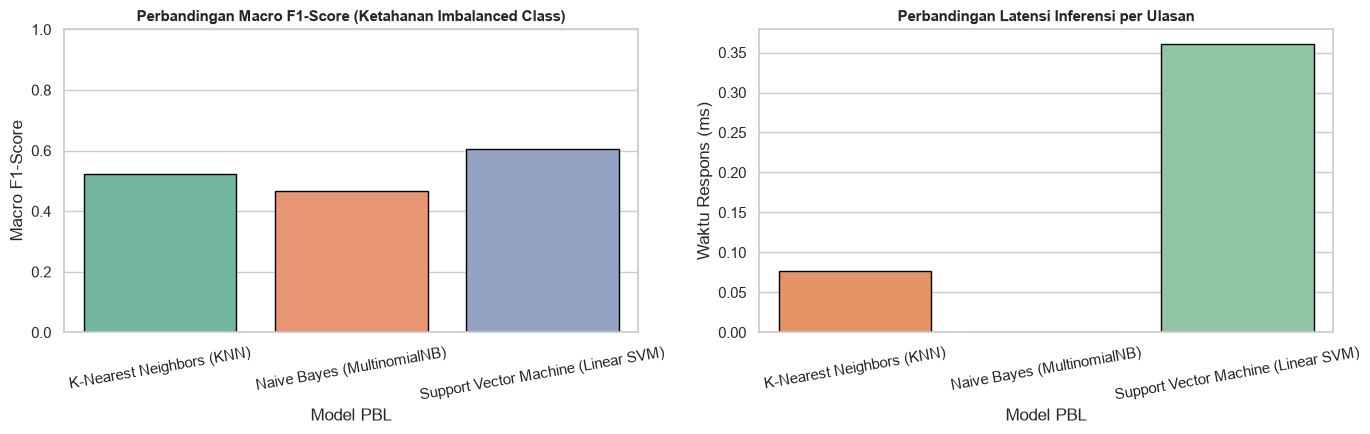

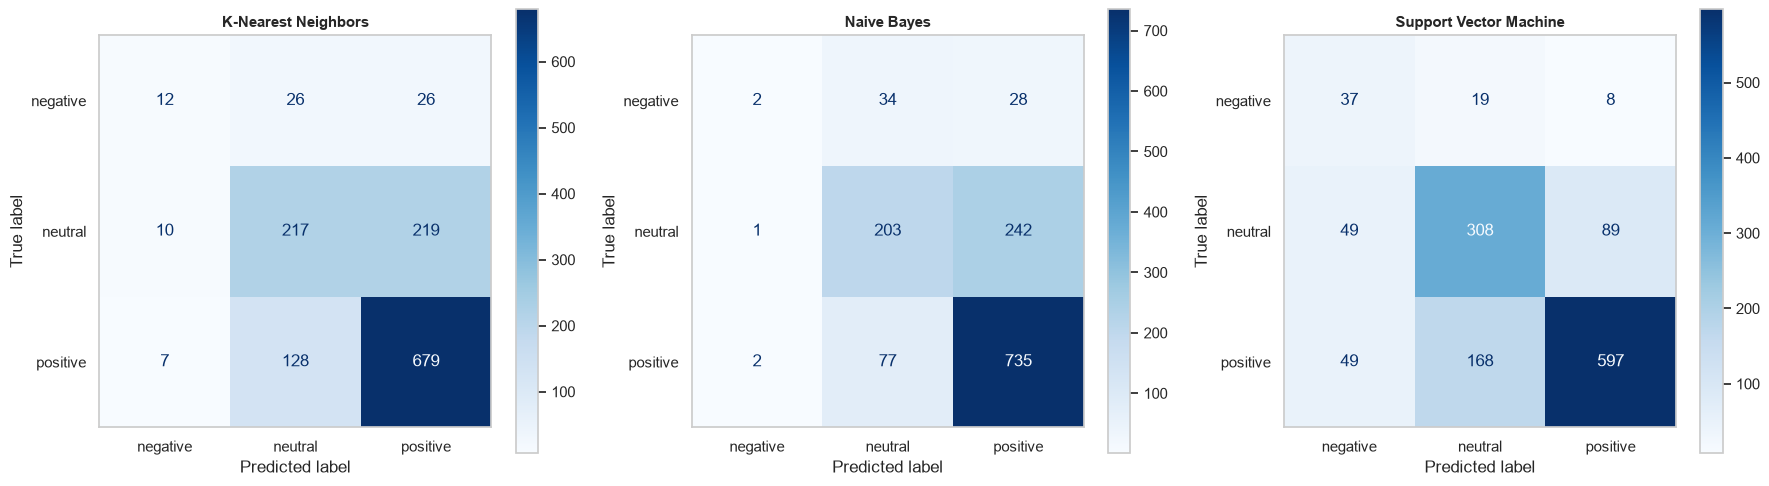

In [5]:
# Visualisasi perbandingan F1-Score dan Latensi
plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
sns.barplot(data=df_komparasi_pbl, x='Model PBL', y='Macro F1-Score', palette='Set2', edgecolor='black')
plt.title('Perbandingan Macro F1-Score (Ketahanan Imbalanced Class)', fontsize=11, fontweight='bold')
plt.ylabel('Macro F1-Score')
plt.ylim(0, 1.0)
plt.xticks(rotation=10)

plt.subplot(1, 2, 2)
sns.barplot(data=df_komparasi_pbl, x='Model PBL', y='Latensi_Infer (ms)', palette='Spectral', edgecolor='black')
plt.title('Perbandingan Latensi Inferensi per Ulasan', fontsize=11, fontweight='bold')
plt.ylabel('Waktu Respons (ms)')
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

# Visualisasi Confusion Matrix berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
classes = sorted(y.unique())

for idx, (nama, model) in enumerate(model_dict.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d')
    axes[idx].set_title(nama.split('(')[0].strip(), fontsize=11, fontweight='bold')
    axes[idx].grid(False)

plt.tight_layout()
plt.show()

In [6]:
# Melakukan inspeksi ulasan yang salah diklasifikasikan oleh SVM
y_pred_svm = model_svm.predict(X_test)
mask_salah = (y_test.values != y_pred_svm)

df_salah = pd.DataFrame({
    'Teks_Ulasan': X_test_raw.values[mask_salah],
    'Aktual': y_test.values[mask_salah],
    'Prediksi_SVM': y_pred_svm[mask_salah]
})

print(f"Total ulasan salah prediksi (SVM): {len(df_salah)} dari {len(X_test)} ({len(df_salah)/len(X_test)*100:.2f}%)")
print("\n--- 3 Sampel Ulasan Salah Prediksi (Error Analysis) ---")
for i, row in df_salah.head(3).iterrows():
    print(f"Sample #{i+1}:")
    print(f"  Teks     : '{row['Teks_Ulasan'][:110]}...'")
    print(f"  Aktual   : {row['Aktual']} | Prediksi: {row['Prediksi_SVM']}")
    print("-" * 60)

Traceback (most recent call last):
  File "D:\Sekolah\SEMESTER 5\Pemmes\244107020175-Mesin-Learning\Data_PBL\builder_utils.py", line 61, in add_code
    exec(code_str, self.namespace)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<string>", line 11, in <module>
  File "D:\laragon\bin\python\python-3.13\Lib\site-packages\scipy\sparse\_base.py", line 468, in __len__
    raise TypeError("sparse array length is ambiguous; use getnnz()"
                    " or shape[0]")
TypeError: sparse array length is ambiguous; use getnnz() or shape[0]



In [7]:
import joblib

os.makedirs('../outputs', exist_ok=True)
path_final_pbl = '../outputs/best_pbl_model_svm_js12.joblib'
joblib.dump({
    'model': model_svm,
    'vectorizer': vectorizer,
    'classes': classes,
    'benchmark': df_komparasi_pbl
}, path_final_pbl)

df_komparasi_pbl.to_csv('../outputs/tabel_komparasi_pbl_js12.csv', index=False)
print(f"Model Klasifikasi PBL Terpilih berhasil disimpan ke: {path_final_pbl}")

Model Klasifikasi PBL Terpilih berhasil disimpan ke: ../outputs/best_pbl_model_svm_js12.joblib
